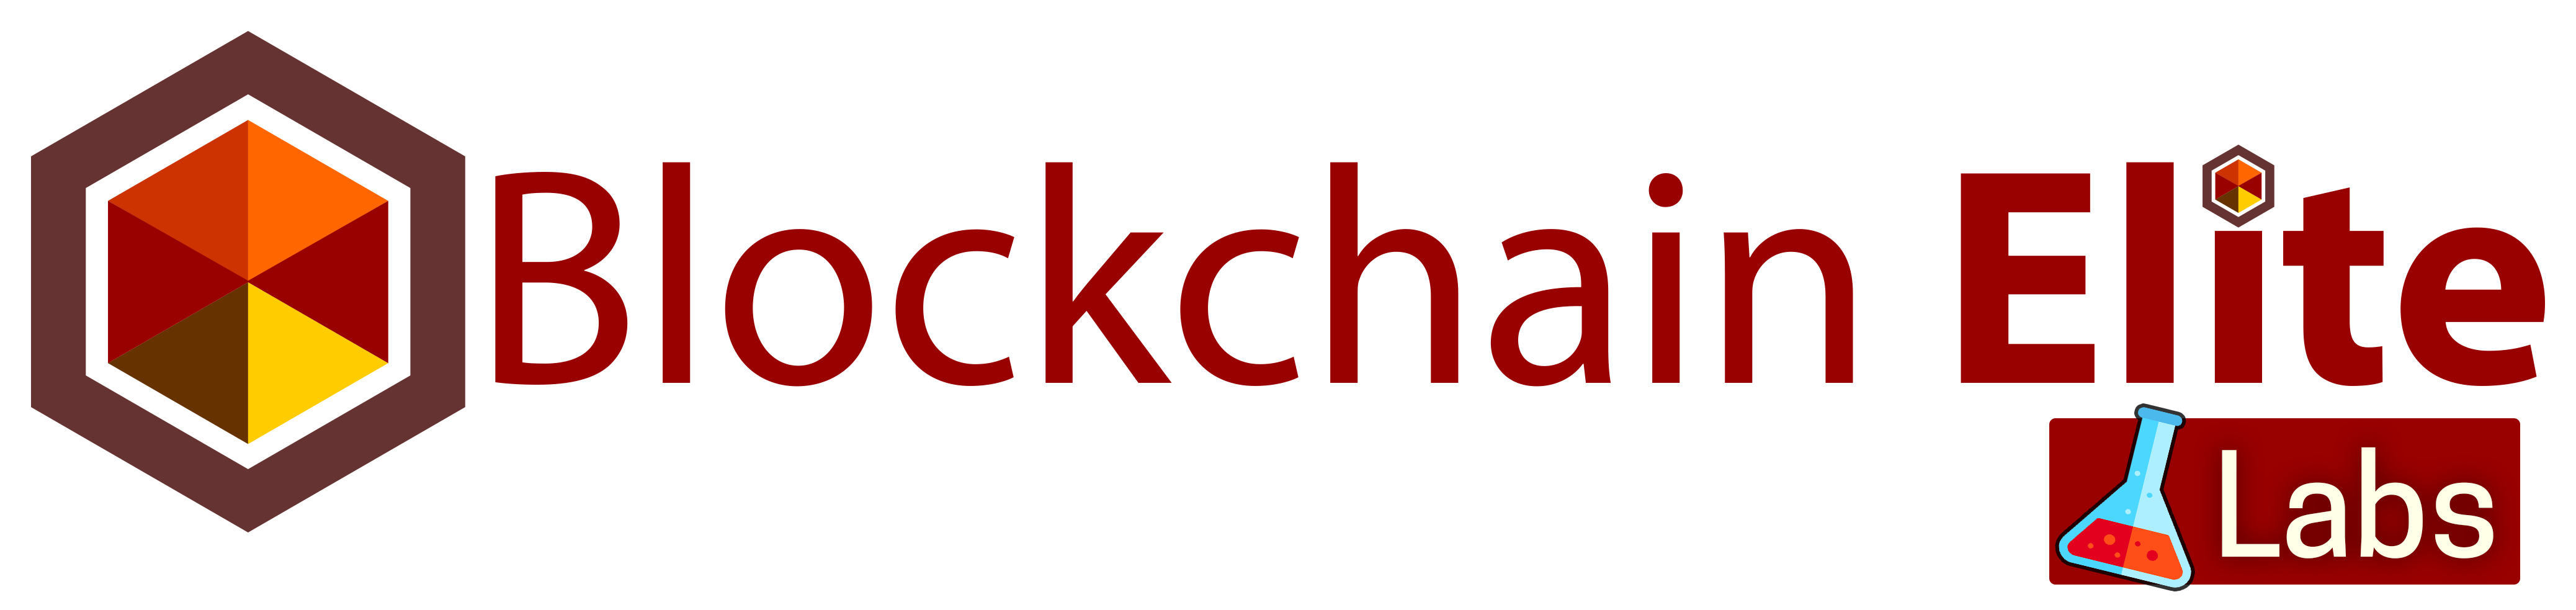

# Welcome to this Notebook created by Blockchain-Elite Labs

Version: August 2024 - V0.3

The goal of this notebook is to show how Harmonia can improve your trading strategy. We will provide here a start point to analyse Harmonia comparing to basic trading strategies and show how IA can improve winning rate.

### Requirements

In [52]:
!pip install pandas
!pip install numpy
!pip install plotly
!pip install tqdm


You should consider upgrading via the 'C:\Users\alexw\Documents\env_python\trading_research\Scripts\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'C:\Users\alexw\Documents\env_python\trading_research\Scripts\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'C:\Users\alexw\Documents\env_python\trading_research\Scripts\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'C:\Users\alexw\Documents\env_python\trading_research\Scripts\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np
import plotly
import plotly.express as px
import plotly.graph_objects as go
from tqdm import tqdm
import datetime

In [3]:
import warnings
warnings.filterwarnings('ignore')

### Import data

On this notebook, we will compare Harmonia 2022 performance against Harmonia 2024 update.

First, we will import Harmonia 2022 and Harmonia 2024 official backtests that you can find directly on the website, or github

In [4]:
# Import Harmonia
harmonia_2022 = pd.read_csv("https://github.com/blockhain-elite-labs/harmonia-v20.1-82-backtests/raw/main/harmonia-20.1-82-2022-market-26months.zip")
harmonia_2024 = pd.read_csv("https://github.com/blockhain-elite-labs/harmonia-v20.1-82-backtests/raw/main/harmonia-20.1-82-2024-market-9months.zip")

Now, we will create a global dataframe with both Harmonia data and market data to "emulate" real time

In [5]:
harmonia_2022["open_date"] = pd.to_datetime(harmonia_2022["open_date"])
harmonia_2024["open_date"] = pd.to_datetime(harmonia_2024["open_date"])

In [6]:
# rename harmonia_2022 and harmonia_2024 "harmonia_prediction" to append network version
harmonia_2022.rename(columns={"harmonia_prediction":"harmonia_prediction_2022"}, inplace=True)
harmonia_2024.rename(columns={"harmonia_prediction":"harmonia_prediction_2024"}, inplace=True)

In [7]:
harmonia_2022 = harmonia_2022.set_index("open_date")
harmonia_2024 = harmonia_2024.set_index("open_date")

In [8]:
# just redure the dataframe in order to fit with the smallest backtest available : harmonia_2024
min_date = harmonia_2024.index[0]
max_date = harmonia_2024.index[len(harmonia_2024)-1]

harmonia_2022 = harmonia_2022[min_date:max_date]
harmonia_2024 = harmonia_2024[min_date:max_date]

In [9]:
context = pd.concat([harmonia_2022,harmonia_2024["harmonia_prediction_2024"]], axis=1, join='outer')

In [10]:
# to be as close as possible from REAL trading condition, because of the 15sec.
# delay in Harmonia computation inference time, let's make a 1min delay for harmonia
context["harmonia_prediction_2022_s"] = context["harmonia_prediction_2022"].shift(1)
context["harmonia_prediction_2024_s"] = context["harmonia_prediction_2024"].shift(1)

# now fill missing data
context = context.ffill()

# WARNING: to use it in real time simulation, you only know 1H data when the 1H candle is closed.
# Then, we need to shift the results of the market data by 60min for 1h candle and 5 for 5m candles
five_min_market_data = list(filter(lambda s: "5m" in s, context))
sixty_min_market_data = list(filter(lambda s: "1h" in s, context))

context[five_min_market_data] = context[five_min_market_data].shift(5)
context[sixty_min_market_data] = context[sixty_min_market_data].shift(60)


context_dt = context[60:]

now, we will use `_s` version with a 1min delay for harmonia prediction value that is a conservative approach.

Let's take a look about the computed dataframe that we will use for our Notebook

In [11]:
context_dt.tail()

,open_price,high,low,close,harmonia_prediction_2022,harmonia_prediction_2024,harmonia_prediction_2022_s,harmonia_prediction_2024_s
open_date,,,,,,,,
2024-06-30 23:35:00,3445.19,3447.23,3444.51,3446.28,-0.072,-0.068,-0.042,-0.082
2024-06-30 23:40:00,3446.22,3446.22,3442.38,3442.38,-0.046,-0.067,-0.072,-0.068
2024-06-30 23:45:00,3442.38,3442.39,3438.70,3440.45,-0.069,-0.074,-0.046,-0.067
2024-06-30 23:50:00,3440.45,3442.08,3439.50,3441.61,-0.071,-0.081,-0.069,-0.074
2024-06-30 23:55:00,3441.61,3442.40,3437.80,3438.16,-0.048,-0.073,-0.071,-0.081


Let's print the avaiable columns for our practical backtests:

In [12]:
list(context_dt.columns)

['open_price',
 'high',
 'low',
 'close',
 'harmonia_prediction_2022',
 'harmonia_prediction_2024',
 'harmonia_prediction_2022_s',
 'harmonia_prediction_2024_s']

**Conclusion**

We have imported Harmonia prediction and other useful market data and common indicator and we are ready to go.

### Long Case: Create winning scenarios with a basic trading strategy


The goal is to calculate for each candle if we can win a basic trade or not. We will add the result of this calculus as a new column in our dataframe.

Let's define a basic trade (we will only check Long trades in this chapter) :

In [13]:
# Long TP objective:
obj_up = 0.01 # 1% up from

# Stop Loss :
stop_loss = 0.005 # 0.05% stoploss

# Maximum trade time, if we didn't reach TP or SL, we will close trade and pretend it reaches SL (also conservative approach)
obj_time = datetime.timedelta(hours=8)

# Create the column result
COLUMN_OBJ_NAME = f"SIMPLE_LONG_STRAT"

print(f"We will add {COLUMN_OBJ_NAME} column to dataframe")

We will add SIMPLE_LONG_STRAT column to dataframe


Now, we will calculate all winning and loosing candle :

In [14]:
# A candle wins if, on the obj_time next rows, it doesn't reach SL and reaches TP
def win_condition(df):
    tp_reached = df["high"].max() >= df.iloc[0]["open_price"] * (1+obj_up)
    sl_reached = df["low"].min() <= df.iloc[0]["open_price"] * (1-stop_loss)

    return (tp_reached and not sl_reached) or (tp_reached and  df["high"].idxmax() < df["low"].idxmin())

indexes = list(context_dt.index)

for i in tqdm(indexes):
    context_dt.loc[i, COLUMN_OBJ_NAME] = win_condition(context_dt[i:i+obj_time])

100%|██████████| 86222/86222 [00:57<00:00, 1504.03it/s]


In [15]:
# Take only relevant results ; Remove last obj_time because trade is not ended
context_dt_rdy = context_dt[:context_dt.index[-1] - obj_time]

**Conclusion:** We have defined for every 1min candle if we could win a potential defined trade, using a TP, SL and time objective

#### Create indicators key event point

Now, using market data available, we will create very very basic trading strategies using Harmonia

In [16]:
EVENTS = set()

#### Harmonia strategy

In [17]:
# Harmonia strategy is to take a trade only when IA think it will be bullish
# But the IA value should not be too much as they are reversal zones.

# Let's test 2 different scenarios: harmonia value reaching 0.12 and 0.14
TRIGGER_UP = [0.12,0.14]

# Possible rollover area, don't take a trade if it's too much
TOO_MUCH  = 0.30


In [18]:
for harmonia in ["harmonia_prediction_2022_s", "harmonia_prediction_2024_s"]:
    for trig in TRIGGER_UP:
        EVENT_HARMONIA_NAME = "event_" + str(harmonia) + "_" + str(trig)
        EVENTS.add(EVENT_HARMONIA_NAME)
        context_dt_rdy[EVENT_HARMONIA_NAME] = (context_dt_rdy[harmonia] > trig) & (context_dt_rdy[harmonia] < TOO_MUCH)

#### LUCK strategy

In [19]:
# LUCK strategy is to take everytime a trade, no matter what happen (we will discuss why we add LUCK strategy after)
EVENT_LUCK_NAME = "event_luck"
EVENTS.add(EVENT_LUCK_NAME)
context_dt_rdy[EVENT_LUCK_NAME] = True

#### Let's see the results of our key event point regarding the trading strategy

#### Calculating results

We will calculate results grouped by month

In [20]:
# we will create different metrics to see results with a dictionnary. Key is the strategy name and value is the result

# gives winrate in %
results_winrate = {}

# gives raw winrate numbers
results_occurences = {}

# gives how much events covers total winning possible candles
results_cover = {}

# gives the relative performance of an indicator compared to LUCK strategy (bias)
results_relative = {}

# gives the relative performance between harmonia 2022 and harmonia 2024
results_harmonia_relative = {}

In [21]:
nb_total_objectives = len(context_dt_rdy[context_dt_rdy[COLUMN_OBJ_NAME]])
print("Total number of candles to find: " + str(nb_total_objectives))
print("Total candles: " + str(len(context_dt_rdy)) + "\n")
print("Pure luck probability finding a winning candle: " + str(round((nb_total_objectives/len(context_dt_rdy))*100,2)) + "%")

Total number of candles to find: 26060
Total candles: 86126

Pure luck probability finding a winning candle: 30.26%


In [22]:
MONTHS = [name for name, group in context_dt_rdy.groupby(pd.Grouper(axis=0, freq='M'))]

In [23]:
for event in EVENTS:
    # calculate winrate for each strategies, and group this by each month
    months_winrate = []
    months_occurences = []

    for name, group in context_dt_rdy.groupby(pd.Grouper(axis=0, freq='M')):
        win_condition = (group[event]) & (group[COLUMN_OBJ_NAME])
        occurences = len(group[group[event]])
        wins = len(group[win_condition])
        winrate = round(wins / occurences, 4)
        months_winrate.append(winrate)
        months_occurences.append(wins)

    results_winrate[event] = months_winrate
    results_occurences[event] = months_occurences

In [24]:
# We compute the relative perf of harmonia 2024 over harmonia 2022 and over luck
for event in EVENTS:
    months_coverage = []
    months_relative_harmonia = []
    months_relative = []
    for month in range(len(results_occurences[EVENT_LUCK_NAME])):
        winrate_current = results_winrate[event][month]
        winrate_ref     = results_winrate[event.replace("2024", "2022")][month]
        months_relative_harmonia.append(round(winrate_current/winrate_ref-1,3))
        months_relative.append(round(winrate_current/results_winrate[EVENT_LUCK_NAME][month]-1,3))
    results_harmonia_relative[event] = months_relative_harmonia
    results_relative[event] = months_relative

Conclusion: We have calculated the results. Let's see it !

#### Results on graphs

In [25]:
def print_graph(results, showlist, title, mode="lines+markers"):
    figures = []
    for event in showlist:
        figure = go.Scatter(mode=mode, x=MONTHS, y=results[event], name=event, text=results[event], textposition='top center')
        figures.append(figure)
    fig = go.Figure(figures)
    fig.update_layout(title=dict(text=title, x=0.5))
    fig.show()

#### Pure luck analysis

Let's start by showing pure luck over months

In [26]:
print_graph(results_winrate, [EVENT_LUCK_NAME], "Pure luck winrate over months")

The graph shows, because of the bullish / bearish trend that changes each months, that the "LONG pure luck" winrate varies from months to months.

It represents the **statistical bias** that we need to consider when we show the winrate of other strategies.

#### Pure luck VS HARMONIA

In [27]:
print_graph(results_winrate, [EVENT_LUCK_NAME] + ["event_harmonia_prediction_2024_s_0.12", "event_harmonia_prediction_2022_s_0.12"], "Pure luck and Harmonia strategies winrate over months for trigger = 0.12")

In [28]:
print("Relative performance improvement between 2022 and 2024 for trigger = 0.12:")
r = pd.DataFrame(columns=["months", "%_perf_harmonia_2024_over_2022", "%_perf_harmonia2022_over_luck", "%_perf_harmonia2024_over_luck"], data=zip(MONTHS,[res * 100 for res in results_harmonia_relative['event_harmonia_prediction_2024_s_0.12']], [res * 100 for res in results_relative['event_harmonia_prediction_2022_s_0.12']], [res * 100 for res in results_relative['event_harmonia_prediction_2024_s_0.12']]))
r

Relative performance improvement between 2022 and 2024 for trigger = 0.12:


,months,%_perf_harmonia_2024_over_2022,%_perf_harmonia2022_over_luck,%_perf_harmonia2024_over_luck
0,2023-09-30,63.7,-14.2,40.4
1,2023-10-31,-7.4,27.3,17.9
2,2023-11-30,17.9,-12.6,3.0
3,2023-12-31,3.8,10.8,15.0
4,2024-01-31,8.8,15.8,26.0
5,2024-02-29,8.0,-10.3,-3.1
6,2024-03-31,6.2,-0.3,5.9
7,2024-04-30,11.1,-14.3,-4.8
8,2024-05-31,21.5,-0.7,20.6
9,2024-06-30,19.9,-6.4,12.2


In [29]:
print_graph(results_winrate, [EVENT_LUCK_NAME] + ["event_harmonia_prediction_2024_s_0.14", "event_harmonia_prediction_2022_s_0.14"], "Pure luck and Harmonia strategies winrate over months for trigger = 0.14")

In [30]:
print("Relative performance improvement between 2022 and 2024 for trigger = 0.14:")
r2 = pd.DataFrame(columns=["months", "%_perf_harmonia_2024_over_2022", "%_perf_harmonia2022_over_luck", "%_perf_harmonia2024_over_luck"], data=zip(MONTHS,[res * 100 for res in results_harmonia_relative['event_harmonia_prediction_2024_s_0.14']], [res * 100 for res in results_relative['event_harmonia_prediction_2022_s_0.14']], [res * 100 for res in results_relative['event_harmonia_prediction_2024_s_0.14']]))
r2

Relative performance improvement between 2022 and 2024 for trigger = 0.14:


,months,%_perf_harmonia_2024_over_2022,%_perf_harmonia2022_over_luck,%_perf_harmonia2024_over_luck
0,2023-09-30,60.4,1.1,62.1
1,2023-10-31,-6.0,43.8,35.1
2,2023-11-30,7.8,-2.6,5.0
3,2023-12-31,1.1,18.1,19.4
4,2024-01-31,18.6,18.8,40.9
5,2024-02-29,5.5,-12.8,-8.0
6,2024-03-31,8.2,0.3,8.6
7,2024-04-30,7.9,-14.8,-8.1
8,2024-05-31,13.9,-1.7,11.9
9,2024-06-30,-8.6,11.4,1.8


### Short Case: Create winning scenarios with a basic trading strategy


The goal is to calculate for each candle if we can win a basic trade or not. We will add the result of this calculus as a new column in our dataframe.

Let's define a basic trade (we will only check Short trades in this chapter) :

In [31]:
# Long TP objective:
obj_up = 0.01 # 1% up from

# Stop Loss :
stop_loss = 0.005 # 0.5% stoploss

# Maximum trade time, if we didn't reach TP or SL, we will close trade and pretend it reaches SL
obj_time = datetime.timedelta(hours=8)

# Create the column result
COLUMN_OBJ_NAME = f"SIMPLE_DOWN_STRAT"

print(f"We will add {COLUMN_OBJ_NAME} column to dataframe")

We will add SIMPLE_DOWN_STRAT column to dataframe


Now, we will calculate all winning and loosing candle :

In [32]:
# A candle wins if, on the obj_time next rows, it doesn't reach SL and reaches TP
def win_condition(df):
    tp_reached = df["low"].min() <= df.iloc[0]["open_price"] * (1-obj_up)
    sl_reached = df["high"].max() >= df.iloc[0]["open_price"] * (1+stop_loss)

    return (tp_reached and not sl_reached) or (tp_reached and  df["high"].idxmax() > df["low"].idxmin())

indexes = list(context_dt.index)

for i in tqdm(indexes):
    context_dt.loc[i, COLUMN_OBJ_NAME] = win_condition(context_dt[i:i+obj_time])

100%|██████████| 86222/86222 [01:02<00:00, 1370.49it/s]


In [33]:
# Take only relevant results ; Remove last obj_time because trade is not ended
context_dt_rdy = context_dt[:context_dt.index[-1] - obj_time]

**Conclusion:** We have defined for every 1min candle if we could win a potential defined trade, using a TP, SL and time objective

#### Create indicators key event point

Now, using market data available, we will create very very basic trading strategies using MACD, RSI and Harmonia

In [34]:
EVENTS = set()

#### Harmonia strategy

In [35]:
# Harmonia strategy is to take a trade only when IA think it will be bullish
# But the IA value should not be too much as they are reversal zones.

# Let's test 2 different scenarios: harmonia value reaching 0.12 and 0.14
TRIGGER_DOWN = [-0.12,-0.14]
TOO_MUCH  = -0.30


In [36]:
for harmonia in ["harmonia_prediction_2022_s", "harmonia_prediction_2024_s"]:
    for trig in TRIGGER_DOWN:
        EVENT_HARMONIA_NAME = "event_" + str(harmonia) + "_" + str(trig)
        EVENTS.add(EVENT_HARMONIA_NAME)
        context_dt_rdy[EVENT_HARMONIA_NAME] = (context_dt_rdy[harmonia] < trig) & (context_dt_rdy[harmonia] > TOO_MUCH)

#### LUCK strategy

In [37]:
# LUCK strategy is to take everytime a trade, no matter what happen (we will discuss why we add LUCK strategy after)
EVENT_LUCK_NAME = "event_luck"
EVENTS.add(EVENT_LUCK_NAME)
context_dt_rdy[EVENT_LUCK_NAME] = True

#### Let's see the results of our key event point regarding the trading strategy

#### Calculating results

We will calculate results grouped by month

In [38]:
# we will create different metrics to see results with a dictionnary. Key is the strategy name and value is the result

# gives winrate in %
results_winrate = {}

# gives raw winrate numbers
results_occurences = {}

# gives how much events covers total winning possible candles
results_cover = {}

# gives the relative performance of an indicator compared to LUCK strategy (bias)
results_relative = {}

# gives the relative performance between harmonia 2022 and harmonia 2024
results_harmonia_relative = {}

In [39]:
nb_total_objectives = len(context_dt_rdy[context_dt_rdy[COLUMN_OBJ_NAME]])
print("Total number of candles to find: " + str(nb_total_objectives))
print("Total candles: " + str(len(context_dt_rdy)) + "\n")
print("Pure luck probability finding a winning candle: " + str(round((nb_total_objectives/len(context_dt_rdy))*100,2)) + "%")

Total number of candles to find: 24618
Total candles: 86126

Pure luck probability finding a winning candle: 28.58%


In [40]:
MONTHS = [name for name, group in context_dt_rdy.groupby(pd.Grouper(axis=0, freq='M'))]

In [41]:
for event in EVENTS:
    # calculate winrate for each strategies, and group this by each month
    months_winrate = []
    months_occurences = []

    for name, group in context_dt_rdy.groupby(pd.Grouper(axis=0, freq='M')):
        win_condition = (group[event]) & (group[COLUMN_OBJ_NAME])
        occurences = len(group[group[event]])
        wins = len(group[win_condition])
        winrate = round(wins / occurences, 4)
        months_winrate.append(winrate)
        months_occurences.append(wins)

    results_winrate[event] = months_winrate
    results_occurences[event] = months_occurences

In [42]:
# We compute the relative perf of harmonia 2024 over harmonia 2022 and over luck
for event in EVENTS:
    months_coverage = []
    months_relative_harmonia = []
    months_relative = []
    for month in range(len(results_occurences[EVENT_LUCK_NAME])):
        winrate_current = results_winrate[event][month]
        winrate_ref     = results_winrate[event.replace("2024", "2022")][month]
        months_relative_harmonia.append(round(winrate_current/winrate_ref-1,3))
        months_relative.append(round(winrate_current/results_winrate[EVENT_LUCK_NAME][month]-1,3))
    results_harmonia_relative[event] = months_relative_harmonia
    results_relative[event] = months_relative

Conclusion: We have calculated the results. Let's see it !

#### Results on graphs

In [43]:
def print_graph(results, showlist, title, mode="lines+markers"):
    figures = []
    for event in showlist:
        figure = go.Scatter(mode=mode, x=MONTHS, y=results[event], name=event, text=results[event], textposition='top center')
        figures.append(figure)
    fig = go.Figure(figures)
    fig.update_layout(title=dict(text=title, x=0.5))
    fig.show()

#### Pure luck analysis

Let's start by showing pure luck over months

In [44]:
print_graph(results_winrate, [EVENT_LUCK_NAME], "Pure luck winrate over months")

The graph shows, because of the bullish / bearish trend that changes each months, that the "LONG pure luck" winrate varies from months to months.

It represents the **statistical bias** that we need to consider when we show the winrate of other strategies.

#### Pure luck VS HARMONIA

In [45]:
print_graph(results_winrate, [EVENT_LUCK_NAME] + ["event_harmonia_prediction_2024_s_-0.12", "event_harmonia_prediction_2022_s_-0.12"], "Pure luck and Harmonia strategies winrate over months for trigger = -0.12")

In [46]:
print("Relative performance improvement between 2022 and 2024 for trigger = -0.12:")
r = pd.DataFrame(columns=["months", "%_perf_harmonia_2024_over_2022", "%_perf_harmonia2022_over_luck", "%_perf_harmonia2024_over_luck"], data=zip(MONTHS,[res * 100 for res in results_harmonia_relative['event_harmonia_prediction_2024_s_-0.12']], [res * 100 for res in results_relative['event_harmonia_prediction_2022_s_-0.12']], [res * 100 for res in results_relative['event_harmonia_prediction_2024_s_-0.12']]))
r

Relative performance improvement between 2022 and 2024 for trigger = -0.12:


,months,%_perf_harmonia_2024_over_2022,%_perf_harmonia2022_over_luck,%_perf_harmonia2024_over_luck
0,2023-09-30,-23.5,95.4,49.4
1,2023-10-31,17.5,10.0,29.2
2,2023-11-30,-0.9,28.9,27.8
3,2023-12-31,3.7,26.3,30.9
4,2024-01-31,0.1,-2.7,-2.6
5,2024-02-29,6.1,50.3,59.4
6,2024-03-31,-4.7,9.8,4.6
7,2024-04-30,9.0,18.2,28.9
8,2024-05-31,-4.9,9.5,4.1
9,2024-06-30,11.9,21.8,36.3


In [47]:
print_graph(results_winrate, [EVENT_LUCK_NAME] + ["event_harmonia_prediction_2024_s_-0.14", "event_harmonia_prediction_2022_s_-0.14"], "Pure luck and Harmonia strategies winrate over months for trigger = -0.14")

In [48]:
print("Relative performance improvement between 2022 and 2024 for trigger = -0.14:")
r2 = pd.DataFrame(columns=["months", "%_perf_harmonia_2024_over_2022", "%_perf_harmonia2022_over_luck", "%_perf_harmonia2024_over_luck"], data=zip(MONTHS,[res * 100 for res in results_harmonia_relative['event_harmonia_prediction_2024_s_-0.14']], [res * 100 for res in results_relative['event_harmonia_prediction_2022_s_-0.14']], [res * 100 for res in results_relative['event_harmonia_prediction_2024_s_-0.14']]))
r2

Relative performance improvement between 2022 and 2024 for trigger = -0.14:


,months,%_perf_harmonia_2024_over_2022,%_perf_harmonia2022_over_luck,%_perf_harmonia2024_over_luck
0,2023-09-30,-30.9,69.7,17.2
1,2023-10-31,26.3,-0.9,25.2
2,2023-11-30,3.6,32.9,37.7
3,2023-12-31,13.9,26.1,43.7
4,2024-01-31,3.3,2.6,6.0
5,2024-02-29,11.4,41.3,57.4
6,2024-03-31,-9.7,12.6,1.7
7,2024-04-30,10.9,13.0,25.4
8,2024-05-31,4.0,0.9,5.0
9,2024-06-30,5.1,24.1,30.4


In [49]:
context_dt.columns

Index(['open_price', 'high', 'low', 'close', 'harmonia_prediction_2022',
       'harmonia_prediction_2024', 'harmonia_prediction_2022_s',
       'harmonia_prediction_2024_s', 'SIMPLE_LONG_STRAT', 'SIMPLE_DOWN_STRAT'],
      dtype='object')

### Automatic Trading with Harmonia
Write
**Rules:**

- **Stop Loss:** 0.5%
- **Take Profit:** 1%
- **Trigger:** 0.14
- **OverTrend:** 0.3
- **Duration:** 8 hours
- **Comission:** 0.01%

1. **Long Position:**
   - Enter a long position if the Harmonia value is between 0.14 and 0.3.
   - Close the position when either:
     - The time duration reaches 8 hours, or
     - The stop loss or take profit is reached.

2. **Short Position:**
   - Enter a short position if the Harmonia value is between -0.14 and -0.3.
   - Close the position when either:
     - The time duration reaches 8 hours, or
     - The stop loss or take profit is reached.




In [3]:
import pandas as pd
import datetime
import plotly.graph_objects as go
from tqdm import tqdm 
df = pd.read_csv("https://github.com/blockhain-elite-labs/harmonia-v20.1-82-backtests/raw/main/harmonia-20.1-82-2024-market-9months.zip")
df["open_date"] = pd.to_datetime(df["open_date"])
df.rename(columns={"harmonia_prediction":"harmonia_prediction_2024"}, inplace=True)
df = df.set_index("open_date")
df.columns = [col.capitalize() for col in df.columns]
df.rename(columns={
    "Open_price": "Open"
}, inplace=True)


## Multiple functions which are already coded.
An important function is _backtesting_process which backtests a configuration.

In [4]:
def build_ema(df:pd.DataFrame, column_name:str, period:int)->None:
    ema_name = f"ema_{column_name}_{period}"
    df[ema_name] = df[column_name].ewm(span=period, adjust=False).mean()
    return ema_name

def _backtesting_process(config:dict, df:pd.DataFrame):
    """
    function to be used to backtest
    """
    # Initialize variables
    positions = []
    trades = []
    saved = config["SAVED"] if "SAVED" in config.keys() else False
    ema_column = build_ema(df, "Open", config["EMA"]["period"]) if config["EMA"]["period"]>0 else False
    commission = config["comission"]
        
    def save(index, price, position, trades):
        position['status'] = 'closed'
        position['exit_time'] = index
        position['exit_price'] = price
        trades.append(position)
        positions.remove(position)

    # Add this line to enable tqdm for pandas DataFrames
    tqdm.pandas()

    # Iterating through rows of a DataFrame with tqdm for progress bar
    for index, row in tqdm(df.iterrows(), total=len(df)):
        price = row['Open']
        high = row['High']
        low = row['Low']
        harmonia_signal = row['Harmonia_prediction_2024']
        if ema_column:
            ema_value = row[ema_column]

        # Check for open positions and update their status
        for position in positions[:]:
            trade_duration = (index - position['entry_time']).total_seconds()

            # Check for time limit
            if trade_duration >= config['TIME_LIMIT']:
                save(index=index, price=price,position=position, trades=trades)
                continue

            # Check for stop loss or take profit
            if position['type'] == 'long':
                if low <= position['sl']:
                    save(index=index, price=position['sl'] ,position=position, trades=trades)
                elif high >= position['tp']:
                    save(index=index, price=position['tp'] ,position=position, trades=trades)
                
                
            elif position['type'] == 'short':
                if high >= position['sl']:
                    save(index=index, price=position['sl'] ,position=position, trades=trades)
                elif low <= position['tp']:
                    save(index=index, price=position['tp'] ,position=position, trades=trades)

        # Open new positions based on Harmonia signal
        if harmonia_signal >= config["TRIGGER"] and harmonia_signal < config["OVER_TREND"]:
            if not ema_column:
                sl = (1 - config["SL"]) * price
                tp = (1 + config["TP"]) * price
                positions.append({
                    'type': 'long',
                    'entry_time': index,
                    'entry_price': price,
                    'sl': sl,
                    'tp': tp,
                    'status': 'open'
                })
            elif price>ema_value: # si on a une colonne ema et si le prix est supérieur à l'EMA <=> phase haussière on obéit
                sl = (1 - config["SL"]) * price
                tp = (1 + config["TP"]) * price
                positions.append({
                    'type': 'long',
                    'entry_time': index,
                    'entry_price': price,
                    'sl': sl,
                    'tp': tp,
                    'status': 'open'
                })
        elif harmonia_signal <= -config["TRIGGER"] and harmonia_signal > -config["OVER_TREND"]:
            if not ema_column:
                sl = (1 + config["SL"]) * price
                tp = (1 - config["TP"]) * price
                positions.append({
                    'type': 'short',
                    'entry_time': index,
                    'entry_price': price,
                    'sl': sl,
                    'tp': tp,
                    'status': 'open'
                })
            elif price<ema_value:
                sl = (1 + config["SL"]) * price
                tp = (1 - config["TP"]) * price
                positions.append({
                    'type': 'short',
                    'entry_time': index,
                    'entry_price': price,
                    'sl': sl,
                    'tp': tp,
                    'status': 'open'
                })
            else:
                pass
    if not trades:
        # If no trades were made, return empty results
        return pd.Series(dtype='float64'), 0, pd.Series(dtype='float64'), config
    
    trade_data = []
    cumulative_percentage = 0

    for trade in trades:
        if trade['type'] == 'long':
            trade_return = ((1-commission)*trade['exit_price'] - (1+commission)*trade['entry_price']) / trade['entry_price'] * 100
        else:  # short
            trade_return = ((1-commission)*trade['entry_price'] - (1+commission)*trade['exit_price']) / trade['entry_price'] * 100
        cumulative_percentage += trade_return
        trade_data.append(
            {
                'trade_entry_time': trade['entry_time'],
                "trade_return":trade_return,
                "entry_price": trade['entry_price'],
                "exit_price":trade['exit_price'],
                "trade_type":trade['type'],
                "trade_exit_time":trade['exit_time'],
                "trade_tp":trade["tp"],
                "trade_sl":trade["sl"],
                "trade_return":trade_return
                    }
            )
        
    
    trade_df = pd.DataFrame(trade_data)
    if saved:
        trade_df.to_csv(f"trades_harmonia_automatic_tp_{config['TP']}_sl_{config['SL']}_TRIGGER_{config['TRIGGER']}_OVERTREND_{config['OVER_TREND']}_TIMELIMIT_{hours}h_trading_comission_{commission}.csv")
    trade_df['date'] = pd.to_datetime(trade_df['trade_entry_time'])
    trade_df['month'] = trade_df['date'].dt.to_period('W')
    # Calculate cumulative returns per month
    monthly_returns = trade_df.groupby('month')['trade_return'].sum().cumsum()
    return monthly_returns, cumulative_percentage, trade_df, config

In [5]:
def plot_one_backtest(hours:int, config:dict):
    """
    plot_one_backtest 
    
    Example:
    hours  = 8 # time duration of a trade
    commission = 0.01/100 # comission
    config = {
        "TP": 0.01,   # Take Profit (1%)
        "SL": 0.002,  # Stop Loss (0.5%)
        "TRIGGER": 0.1, # Trigger 
        "OVER_TREND": 0.3, # Over Trend
        "TIME_LIMIT": datetime.timedelta(hours=hours).total_seconds(),  # Time limit of 8 hours in seconds
        "EMA":{
            "period":0
        }, #EMA condition period 0 means no ema used
        "SAVED":True, # Save Data
        "comission":commission # Comission
    }
    plot_one_backtest(hours, commission, config)

    Args:
        hours (int): window size before we end the trade
        commission (float): comission is broker dependant
        config (dict): dictionnary containing the configuration of the strategy
    """
    comission = config["comission"]
    fig = go.Figure()
    monthly_returns, cumulative_percentage, trade_df, config = _backtesting_process(config, df)
    print(f"Cumulative Percentage Returns:{cumulative_percentage}")
    print(f"Nombre de Trades:{len(trade_df)}")
    fig.add_trace(go.Scatter(
        x=monthly_returns.index.to_timestamp(), 
        y=monthly_returns.values, 
        mode='lines+markers', 
        name=f"TP_{config['TP']} ,SL_{config['SL']} ,Trigger_{config['TRIGGER']} ,OverTrend_{config['OVER_TREND']} Cumulative Return"
    ))
    fig.update_layout(title=f"Cumulative Return per Week, TP_{config['TP']} ,SL_{config['SL']} ,Trigger_{config['TRIGGER']} ,OverTrend_{config['OVER_TREND']}, Comission_{comission}, Time duration max_{hours}h",
                        xaxis_title='Month',
                        yaxis_title='Cumulative Return (%)',
                        xaxis=dict(type='date'),
                        yaxis=dict(title='Cumulative Return (%)'),
                        template='plotly_dark')
    fig.show()

You can play with it:

In [9]:
hours  = 8 # time duration of a trade
commission = 0.015/100 # comission
config = {
    "TP": 0.01,   # Take Profit (1%)
    "SL": 0.002,  # Stop Loss (0.5%)
    "TRIGGER": 0.1, # Trigger 
    "OVER_TREND": 0.3, # Over Trend
    "TIME_LIMIT": datetime.timedelta(hours=hours).total_seconds(),  # Time limit of 8 hours in seconds
    "EMA":{
        "period":0
    }, #EMA condition period 0 means no ema used
     "SAVED":True, # Save Data
    "comission":commission # Comission
}
plot_one_backtest(hours, commission, config)

100%|██████████| 86282/86282 [00:05<00:00, 15381.45it/s]


Cumulative Percentage Returns:116.03467465703868
Nombre de Trades:8996


### Conclusion

The aim of this Python Notebook was to show you that Harmonia can actually **improve your strating strategy**.

Indeed, Harmonia indicator gives you **high quality key point** for your trades. It can create statistically benefits strategy because the winrate is close or up to 33% (Risk reward ratio of the selected trading strategy was 2)


You should try to use Harmonia combined with your strategy using Backtests available at https://www.blockchain-elite.fr/download-backtests/

Do not hesitate to clone this Python Notebook and experience backtests by yourself.


Do not hesitate to learn more about Harmonia indicators here : https://www.blockchain-elite.fr/artificial-intelligence-crypto-indicator-harmonia/


Blockchain Elite Labs whishes you a happy and profitable trading experience with Harmonia :)

*Disclaimer: Blockchain Elite Labs provides information and content for educational and informational purposes only. None of the content published by Blockchain Elite Labs constitutes financial or investment advice, and it should not be construed as such. Trading and investing in cryptocurrencies and other financial instruments involve a high level of risk, and individuals should carefully consider their financial situation and risk tolerance before making any investment decisions.*

*Blockchain Elite Labs does not endorse any specific trading or investment strategy, and any decision to engage in trading or investment activities should be based on your own independent research and evaluation of your financial circumstances. Past performance is not indicative of future results, and there is no guarantee that any particular outcome or result will be achieved.*

*Blockchain Elite Labs is not responsible for any loss or damage, including without limitation, any loss of profit, which may arise directly or indirectly from the use of or reliance on such information. You should seek the advice of a qualified financial professional before making any investment decisions.*

*Please be aware that the cryptocurrency market is highly volatile and subject to rapid and unpredictable changes. It is important to be aware of the risks involved and to carefully consider your investment objectives before participating in any trading or investment activities.*